# Prétraitement des prix agricoles

Ce notebook prépare les données mensuelles nécessaires à la comparaison des méthodes naïve, SARIMA et ETS.

L’étude porte sur quatre séries :
- Canola : Alberta et Saskatchewan.
- Maïs-grain : Ontario et Québec.

La période étudiée va de janvier 1985 à août 2026.
Les prix sont exprimés en dollars par tonne métrique.
Les fichiers sources sont conservés sans modification.

## Localisation des fichiers sources

Nous identifions le dossier data du projet et vérifions la présence des fichiers canola.csv et mais.csv. Cette étape permet de contrôler les chemins avant de charger les données.

In [61]:
from pathlib import Path

# Retrouver le dossier principal du projet
dossier_courant = Path.cwd()
racine = (
    dossier_courant
    if (dossier_courant / "data").is_dir()
    else dossier_courant.parent
)

dossier_data = racine / "data"

print("Dossier des données :", dossier_data)
print("Canola trouvé :", (dossier_data / "canola.csv").exists())
print("Maïs trouvé :", (dossier_data / "mais.csv").exists())

Dossier des données : c:\Users\lahmi\projet-prix-agricoles\data
Canola trouvé : True
Maïs trouvé : True


## Chargement des données

Les deux fichiers CSV sont chargés dans des tableaux pandas.
L’encodage cp1252 permet de lire correctement les caractères accentués.

Nous affichons les dimensions et les cinq premières lignes de chaque tableau pour vérifier la structure des données importées.

In [62]:
import pandas as pd

# Lire les deux fichiers sans les modifier
canola = pd.read_csv(
    dossier_data / "canola.csv",
    encoding="cp1252"
)

mais = pd.read_csv(
    dossier_data / "mais.csv",
    encoding="cp1252"
)

# Afficher les dimensions et les premières lignes
print("Canola - lignes, colonnes :", canola.shape)
display(canola.head())

print("Maïs - lignes, colonnes :", mais.shape)
display(mais.head())

Canola - lignes, colonnes : (1000, 5)


,date,province,culture,prix,unité
0,1/1/1985,Saskatchewan,Canola,339.82,Dollars par tonne métrique
1,1/1/1985,Alberta,Canola,342.00,Dollars par tonne métrique
2,2/1/1985,Saskatchewan,Canola,341.26,Dollars par tonne métrique
3,2/1/1985,Alberta,Canola,347.27,Dollars par tonne métrique
4,3/1/1985,Saskatchewan,Canola,349.77,Dollars par tonne métrique


Maïs - lignes, colonnes : (1000, 5)


,date,province,culture,prix,unité
0,1/1/1985,Québec,Maïs-grain,161.01,Dollars par tonne métrique
1,1/1/1985,Ontario,Maïs-grain,133.85,Dollars par tonne métrique
2,2/1/1985,Québec,Maïs-grain,164.95,Dollars par tonne métrique
3,2/1/1985,Ontario,Maïs-grain,132.67,Dollars par tonne métrique
4,3/1/1985,Québec,Maïs-grain,154.32,Dollars par tonne métrique


## Organisation des données

Les deux tableaux sont regroupés pour appliquer les mêmes contrôles aux quatre séries. Les colonnes "culture" et "province" permettent de distinguer chaque série.

La colonne "unité" est renommée "unite". Les dates sont converties depuis le format mois/jour/année, puis les observations sont triées par culture, province et ordre chronologique.

In [63]:
# Regrouper les deux tableaux
df = pd.concat([canola, mais], ignore_index=True)

# Simplifier le nom de la colonne unité
df = df.rename(columns={"unité": "unite"})

# Convertir les dates : mois/jour/année dans les fichiers sources
df["date"] = pd.to_datetime(df["date"], format="%m/%d/%Y")

# Trier chaque série par ordre chronologique
df = df.sort_values(
    ["culture", "province", "date"]
).reset_index(drop=True)

display(df.head())
print("Nombre total de lignes :", len(df))
print("Type de la colonne date :", df["date"].dtype)

,date,province,culture,prix,unite
0,1985-01-01,Alberta,Canola,342.00,Dollars par tonne métrique
1,1985-02-01,Alberta,Canola,347.27,Dollars par tonne métrique
2,1985-03-01,Alberta,Canola,350.04,Dollars par tonne métrique
3,1985-04-01,Alberta,Canola,363.84,Dollars par tonne métrique
4,1985-05-01,Alberta,Canola,354.58,Dollars par tonne métrique


Nombre total de lignes : 2000
Type de la colonne date : datetime64[ns]


## Contrôle des valeurs manquantes et des doublons

Pour chaque série, nous vérifions les dates de début et de fin, le nombre de lignes et le nombre de prix manquants.

Nous recherchons également les doublons selon la combinaison
"date + province + culture", qui doit être unique.
Les anomalies sont affichées avant toute correction.

In [64]:
# Résumé des quatre séries
resume = df.groupby(["culture", "province"]).agg(
    debut=("date", "min"),
    fin=("date", "max"),
    nombre_lignes=("date", "size"),
    prix_manquants=("prix", lambda x: x.isna().sum())
)

display(resume)

# Afficher les lignes dont le prix manque
print("Lignes avec un prix manquant :")
display(df[df["prix"].isna()])

# Repérer les observations répétées pour une même série et une même date
doublons = df.duplicated(
    subset=["date", "province", "culture"],
    keep=False
)

print("Nombre de lignes concernées par des doublons :", doublons.sum())
display(df[doublons])

debut        fin  nombre_lignes  prix_manquants
culture    province                                                         
Canola     Alberta      1985-01-01 2026-08-01            500               1
           Saskatchewan 1985-01-01 2026-08-01            500               0
Maïs-grain Ontario      1985-01-01 2026-08-01            500               0
           Québec       1985-01-01 2026-08-01            500               0

Lignes avec un prix manquant :


,date,province,culture,prix,unite
328,2012-05-01,Alberta,Canola,NaN,Dollars par tonne métrique


Nombre de lignes concernées par des doublons : 0


,date,province,culture,prix,unite


## Vérification du calendrier mensuel

Nous comparons les dates de chaque série au calendrier mensuel attendu, de janvier 1985 à août 2026.

Ce contrôle permet de repérer les mois absents et les dates qui ne correspondent pas au calendrier attendu. 

Une ligne présente avec un prix manquant est distinguée d’un mois entièrement absent du tableau.

In [65]:
# Verifier que toutes les dates sont bien le premier jour du mois
# Calendrier mensuel attendu pour les quatre séries
calendrier = pd.date_range(
    start="1985-01-01",
    end="2026-08-01",
    freq="MS"  # Premier jour de chaque mois
)

for (culture, province), groupe in df.groupby(["culture", "province"]):
    dates_presentes = pd.DatetimeIndex(groupe["date"])
    mois_absents = calendrier.difference(dates_presentes)
    dates_inattendues = dates_presentes.difference(calendrier)

    print(f"{culture} - {province}")
    print("  Mois absents :", len(mois_absents))
    print("  Dates hors calendrier :", len(dates_inattendues))

Canola - Alberta
  Mois absents : 0
  Dates hors calendrier : 0
Canola - Saskatchewan
  Mois absents : 0
  Dates hors calendrier : 0
Maïs-grain - Ontario
  Mois absents : 0
  Dates hors calendrier : 0
Maïs-grain - Québec
  Mois absents : 0
  Dates hors calendrier : 0


Les quatre séries ont un calendrier mensuel complet : aucun mois absent et aucune date hors calendrier.

Un mois absent signifie qu’il manque une ligne. Un prix manquant signifie que la ligne existe, mais que son prix est vide, comme pour mai 2012 en Alberta.

### Statistiques descriptives des prix

Nous calculons les statistiques descriptives séparément pour chaque combinaison culture-province, à partir des prix observés avant imputation.
La moyenne et la médiane résument le niveau des prix, tandis que l’écart-type et les quartiles décrivent leur dispersion.

In [66]:
# Statistiques descriptives par culture et province
statistiques = (
    df.groupby(["culture", "province"])["prix"]
    .describe()
    .rename(columns={
        "count": "prix_observes",
        "mean": "moyenne",
        "std": "ecart_type",
        "min": "minimum",
        "25%": "Q1",
        "50%": "mediane",
        "75%": "Q3",
        "max": "maximum"
    })
)

display(statistiques.round(2))

prix_observes  moyenne  ecart_type  minimum      Q1  \
culture    province                                                            
Canola     Alberta               499.0   416.66      161.97   182.67  284.57   
           Saskatchewan          500.0   418.51      167.98   176.96  274.92   
Maïs-grain Ontario               500.0   171.66       59.24    85.61  120.23   
           Québec                500.0   185.43       62.13   102.57  131.99   

                         mediane      Q3  maximum  
culture    province                                
Canola     Alberta        383.87  490.81  1077.97  
           Saskatchewan   383.18  494.68  1101.49  
Maïs-grain Ontario        155.54  206.91   341.54  
           Québec         167.54  220.25   371.00

### Commentaire:
Les prix moyens du canola sont proches en Alberta "416,66 \$/tonne" et en Saskatchewan "418,51 \$/tonne". Pour le maïs-grain, la moyenne est plus élevée au Québec "185,43 \$/tonne" qu’en Ontario "171,66 \$/tonne".

Dans les quatre séries, la moyenne dépasse la médiane, ce qui suggère une influence des prix élevés sur la moyenne. Le canola présente une
dispersion plus importante en dollars par tonne que le maïs.

Les 499 observations pour l’Alberta s’expliquent par le prix manquant de mai 2012, exclu des calculs.

Ces statistiques portent sur des prix nominaux, non corrigés de l’inflation, et résument l’ensemble de la période étudiée.


## Exploration graphique des prix

Nous traçons séparément les quatre séries pour observer leurs évolutions, les périodes de hausse et de baisse et les prix inhabituels.

Cette exploration complète les contrôles de qualité. Un prix extrême n’est pas automatiquement considéré comme une erreur et n’est pas supprimé sans justification.

In [67]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


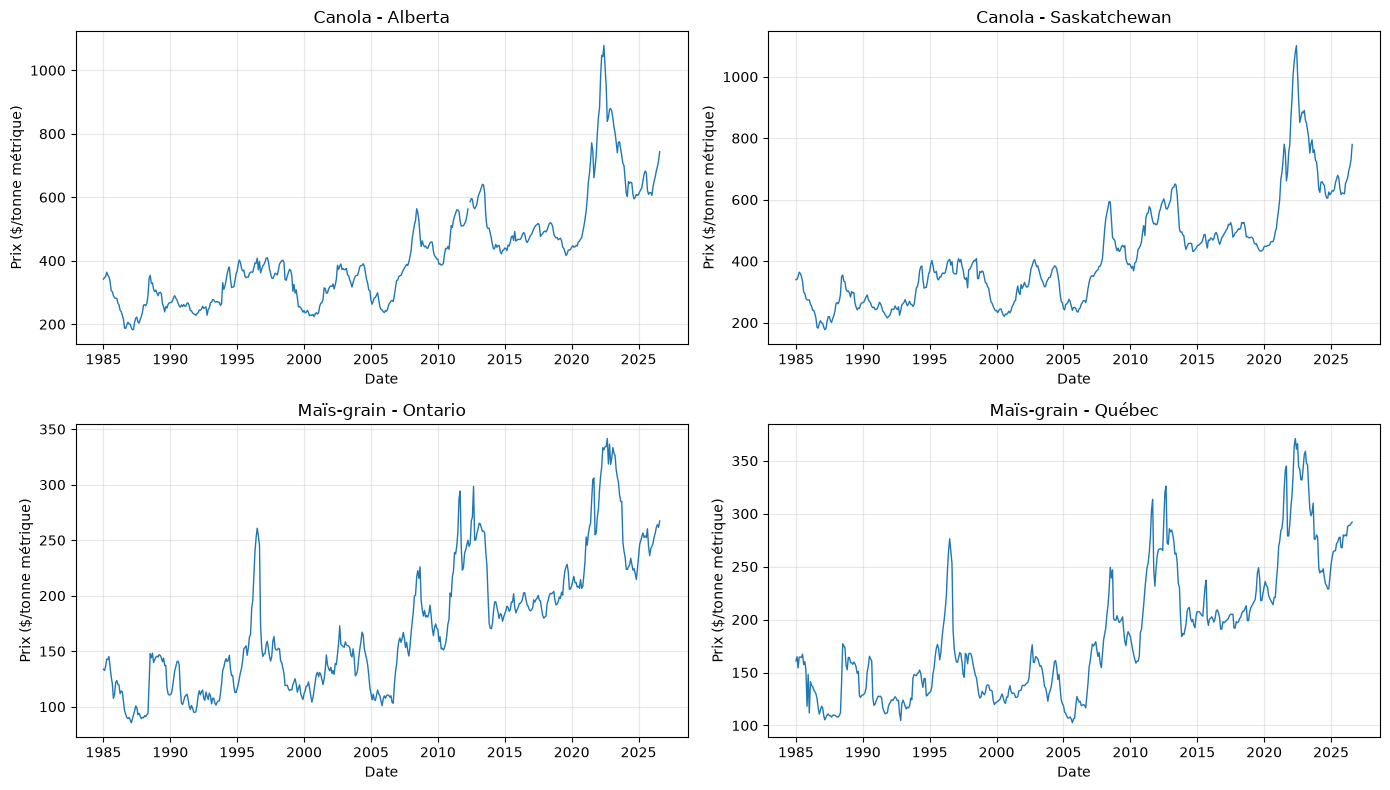

In [68]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

for ax, ((culture, province), groupe) in zip(
    axes.flat,
    df.groupby(["culture", "province"])
):
    ax.plot(groupe["date"], groupe["prix"], linewidth=1)
    ax.set_title(f"{culture} - {province}")
    ax.set_xlabel("Date")
    ax.set_ylabel("Prix ($/tonne métrique)")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Analyse visuelle des prix mensuels

Les graphiques présentent les prix mensuels de janvier 1985 à août 2026, exprimés en dollars par tonne métrique, pour les quatre séries étudiées.

- Canola : les prix en Alberta et en Saskatchewan suivent des évolutions très similaires, avec plusieurs phases de hausse et de baisse.
- Maïs-grain : les prix en Ontario et au Québec présentent également des mouvements proches, malgré des différences de niveau.
- Prix extrêmes : un pic particulièrement marqué apparaît vers 2022 dans les quatre séries. Ces observations sont conservées, car un prix extrême ne constitue pas nécessairement une erreur.
- Saisonnalité : aucun motif annuel répétitif n’est clairement identifiable à cette échelle. Une analyse complémentaire sera nécessaire pour déterminer si une composante saisonnière est pertinente.

Cette exploration décrit les mouvements des prix, mais ne permet pas d’en établir les causes ni de choisir à elle seule le meilleur modèle de prévision.

## Traitement de la valeur manquante

Le prix du canola en Alberta pour mai 2012 est estimé par la moyenne des prix d’avril et de juin 2012. Cette méthode correspond ici à une interpolation linéaire, car un seul mois manque entre deux observations mensuelles connues.

Elle suppose une évolution régulière entre les deux mois voisins. La valeur calculée reste donc une estimation. La colonne "prix_impute" permet de l’identifier et les données originales sont conservées.

L’estimation est effectuée avant le découpage chronologique, car les prix d’avril et de juin 2012 appartiennent à l’entraînement dans les trois découpages retenus. Aucune donnée de validation ou de test n’est utilisée pour ce calcul.


In [69]:
# Conserver les données originales
df_prepare = df.copy()

# Identifier les prix initialement manquants
df_prepare["prix_impute"] = df_prepare["prix"].isna()

# Sélectionner la série du canola en Alberta
serie = (
    (df_prepare["culture"] == "Canola")
    & (df_prepare["province"] == "Alberta")
)

# Calculer la moyenne des prix d'avril et de juin 2012
voisins = df_prepare.loc[
    serie & df_prepare["date"].isin(
        pd.to_datetime(["2012-04-01", "2012-06-01"])
    ),
    "prix"
]

# Repérer mai 2012
mai = serie & (
    df_prepare["date"] == pd.Timestamp("2012-05-01")
)

# Remplacer son prix manquant par la moyenne des deux voisins
df_prepare.loc[mai & df_prepare["prix_impute"], "prix"] = voisins.mean()

# Vérifier le résultat
display(df_prepare[df_prepare["prix_impute"]])
print("Prix encore manquants :", df_prepare["prix"].isna().sum())

,date,province,culture,prix,unite,prix_impute
328,2012-05-01,Alberta,Canola,574.585,Dollars par tonne métrique,True


Prix encore manquants : 0


Le prix estimé pour mai 2012 est de 574,585 $/tonne métrique.
Après ce traitement, aucune valeur de prix ne reste manquante.

## Utilisation des données préparées

Ce notebook documente le prétraitement et l’exploration des fichiers "data/canola.csv" et "data/mais.csv".

Les réglages de l’entraînement, de la validation et du test sont centralisés dans "src/config.py" et décrits dans "docs/protocole.md". Ils sont communs aux méthodes naïve, ETS et SARIMA.